# 02 — Previsão de reeleição de prefeitos: trabalho, máquina ou contexto político?

**Projeto final — Inteligência Artificial (UFPI)** · Autor: *Enrico da Rocha Santos Teixeira*

| | |
|---|---|
| **Objetivo** | Estimar a probabilidade de um prefeito de primeiro mandato ser reeleito, a partir de indicadores disponíveis **antes** da eleição. |
| **Pergunta de pesquisa** | Qual grupo de indicadores (desempenho da gestão, recursos/máquina pública ou contexto político) carrega mais informação para prever a reeleição, e esse padrão muda conforme o porte e a dependência fiscal do município? |
| **Tipo de aprendizado** | Supervisionado — classificação binária (`reeleito` = 1 ou 0). |
| **Natureza da conclusão** | **Preditiva, não causal.** O modelo mostra quais informações ajudam a prever o resultado; não prova que um fator *causa* a reeleição. |

### Contexto e relevância
Desde 1997, prefeitos brasileiros podem disputar um segundo mandato consecutivo. A taxa de sucesso de
quem tenta a reeleição variou muito: 49% em 2016, cerca de 63% em 2020 e cerca de 82% em 2024 (recorde).
Entender se o eleitor recompensa resultados de gestão ("trabalho = continuidade") ou se pesam mais os
recursos à disposição do incumbente ("a máquina fala mais alto") interessa a eleitores, órgãos de
controle, jornalismo de dados e pesquisadores de políticas públicas.

### Escopo
Municípios brasileiros, eleições ordinárias de 2020 e 2024; apenas prefeitos de primeiro mandato que
disputaram a reeleição em eleição competitiva (com pelo menos um adversário com votos). A construção da base
está documentada no notebook `01_construcao_dataset`.

## 1. Reprodutibilidade

Todas as bibliotecas usadas já vêm instaladas no Google Colab. A semente aleatória é fixada para que a
reamostragem (bootstrap) e a validação cruzada produzam sempre os mesmos números.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
                             balanced_accuracy_score, confusion_matrix, roc_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

SEMENTE = 42
np.random.seed(SEMENTE)
print("Python libs -> pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

# Estilo dos gráficos: marcas finas, grade discreta, paleta categórica fixa (mesma cor = mesma categoria)
COR = {"azul": "#2a78d6", "laranja": "#eb6834", "verde": "#1baf7a", "amarelo": "#eda100",
       "texto": "#0b0b0b", "texto2": "#52514e", "grade": "#e4e3df"}
COR_BLOCO = {"Context": COR["azul"], "Public machine": COR["laranja"], "Work": COR["verde"],
             "Campaign money": COR["amarelo"], "All": COR["texto2"]}

def cor_da_config(nome):
    # cor de uma configuração do tipo "<bloco> only"; configurações "All without ..." ficam em cinza claro
    if "without" in nome:
        return COR["grade"]
    return next((c for b, c in COR_BLOCO.items() if nome.startswith(b)), COR["texto2"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "font.size": 10,
    "axes.edgecolor": COR["grade"], "axes.labelcolor": COR["texto2"], "axes.titlecolor": COR["texto"],
    "axes.titleweight": "bold", "axes.grid": True, "grid.color": COR["grade"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": COR["texto2"], "ytick.color": COR["texto2"],
    "legend.frameon": False,
})

Python libs -> pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | matplotlib 3.10.0


## 2. Dados

**Fonte:** dados abertos do Tribunal Superior Eleitoral (candidatos, resultados, coligações e prestação de
contas), da Secretaria do Tesouro Nacional (FINBRA/SICONFI — contas anuais dos municípios), do IBGE
(PIB dos municípios e estimativas de população) e do INEP (IDEB), obtidos via
[Base dos Dados](https://basedosdados.org). São dados públicos, de livre uso com citação da fonte.
O arquivo consolidado (`base_final.csv`) está disponível no repositório [github.com/enricotx/reeleicao-prefeitos](https://github.com/enricotx/reeleicao-prefeitos), e o notebook 01 mostra como
reconstruí-lo do zero.

**Privacidade:** a base não contém nome, CPF, título de eleitor ou partido dos prefeitos.

In [2]:
# Link público do arquivo consolidado (repositório do projeto no GitHub)
URL_DADOS = "https://raw.githubusercontent.com/enricotx/reeleicao-prefeitos/main/base_final.csv"

try:
    base = pd.read_csv(URL_DADOS)
    print("Base carregada do GitHub.")
except Exception as erro:               # alternativa: enviar o arquivo manualmente para o Colab
    print("Não foi possível ler o link (", erro, "). Envie o arquivo base_final.csv:")
    from google.colab import files
    enviado = files.upload()
    base = pd.read_csv(next(iter(enviado)))

base["id_municipio"] = base["id_municipio"].astype(str)
print(base.shape)
base.head()

Base carregada do GitHub.
(5622, 27)


,ano,sigla_uf,id_municipio,id_municipio_tse,reeleito,alvo_margem,pct_votos_anterior,margem_anterior,n_candidatos,troca_partido,...,dependencia_transferencias,pessoal_share,investimento_share,var_pessoal,acel_investimento,cresc_pib_pc_rel,log_populacao,var_ideb,regiao,log_gasto_campanha_pc
0,2020,AC,1200013,1120,0,-0.034020,0.537313,0.321802,4,1,...,0.926529,0.615231,0.035252,0.133225,0.018546,-0.167208,9.632728,0.6,Norte,1.346531
1,2020,AC,1200054,1570,0,-0.129906,0.525911,0.222222,5,0,...,0.948785,0.632479,0.044743,0.153700,0.024293,-0.139444,8.911530,0.6,Norte,0.000000
2,2020,AC,1200104,1058,1,0.237877,0.531406,0.062812,3,0,...,0.920799,0.547110,0.063537,0.095165,0.032526,-0.066838,10.176487,1.1,Norte,1.607819
3,2020,AC,1200138,1007,0,-0.152461,0.298678,0.062057,5,1,...,0.929105,0.596175,0.049361,0.112776,0.008248,-0.225773,9.236593,0.3,Norte,0.000000
4,2020,AC,1200252,1112,0,-0.358898,0.470670,0.120560,4,1,...,0.919161,0.492383,0.060868,0.113152,-0.003257,-0.197497,9.820704,0.7,Norte,1.143337


### Dicionário de variáveis

Os atributos foram organizados em três **blocos**, que correspondem às hipóteses do trabalho. Todos os
indicadores do mandato usam apenas anos **anteriores** à eleição (*t−3* a *t−1*).

| Bloco | Variável | Descrição |
|---|---|---|
| Alvo | `reeleito` | 1 se o prefeito venceu a eleição (em qualquer turno) |
| Contexto político | `pct_votos_anterior`, `margem_anterior` | % de votos e margem sobre o 2º colocado quando foi eleito (1º turno) |
| Contexto político | `n_candidatos` | Número de candidatos com votos na eleição atual |
| Contexto político | `troca_partido` | Disputou por partido diferente daquele pelo qual foi eleito |
| Contexto político | `mesmo_partido_governador`, `coligacao_com_governador` | Alinhamento com o governador em exercício |
| Contexto político | `n_partidos_coligacao` | Tamanho da coligação |
| Contexto político | `idade`, `genero_feminino` | Perfil do prefeito |
| Contexto político | `log_populacao`, `regiao_*` | Porte e região do município |
| Trabalho | `var_ideb` | Variação do IDEB municipal (anos iniciais) durante o mandato |
| Trabalho | `cresc_pib_pc_rel` | Crescimento do PIB per capita relativo ao Brasil |
| Trabalho | `investimento_share` | Investimentos / despesa total |
| Máquina pública | `dependencia_transferencias` | Transferências correntes / receitas correntes |
| Máquina pública | `pessoal_share`, `var_pessoal` | Peso e crescimento da despesa com pessoal |
| Máquina pública | `acel_investimento` | Aumento do investimento no ano pré-eleitoral |
| Dinheiro de campanha | `gasto_campanha_share`, `log_gasto_campanha_pc` | Participação no gasto de campanha do município e gasto per capita |

**Por que separar "máquina pública" de "dinheiro de campanha"?** São recursos diferentes: o primeiro é o
orçamento da prefeitura, que o prefeito controla durante o mandato; o segundo é arrecadado e gasto
**durante a campanha** (agosto a outubro). O gasto de campanha tem um problema adicional de
**causalidade reversa**: candidatos que já são favoritos atraem mais doações e gastam mais. Por isso
também avaliamos um modelo **pré-campanha**, que usa só o que se sabe no registro das candidaturas.

`alvo_margem` (margem na eleição atual) é o próprio resultado e **nunca** é usado como atributo.

In [3]:
REGIOES = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
for r in REGIOES:
    base[f"regiao_{r}"] = (base["regiao"] == r).astype(int)

BLOCOS = {
    "Context": ["pct_votos_anterior", "margem_anterior", "n_candidatos", "troca_partido",
                "mesmo_partido_governador", "coligacao_com_governador", "n_partidos_coligacao",
                "idade", "genero_feminino", "log_populacao"] + [f"regiao_{r}" for r in REGIOES],
    "Work": ["var_ideb", "cresc_pib_pc_rel", "investimento_share"],
    "Public machine": ["dependencia_transferencias", "pessoal_share", "var_pessoal", "acel_investimento"],
    "Campaign money": ["gasto_campanha_share", "log_gasto_campanha_pc"],
}
PRE_CAMPANHA = [c for c in [c for cols in BLOCOS.values() for c in cols] if c not in BLOCOS["Campaign money"]]
TODAS = [c for cols in BLOCOS.values() for c in cols]
ALVO = "reeleito"
assert "alvo_margem" not in TODAS   # proteção contra vazamento

resumo = base.groupby("ano").agg(prefeitos=(ALVO, "size"), taxa_reeleicao=(ALVO, "mean"))
print(resumo.round(3))
print("\nValores ausentes (%):")
print((base[TODAS].isna().mean() * 100).round(1).sort_values(ascending=False).head(10).to_string())

      prefeitos  taxa_reeleicao
ano                            
2020       2998           0.643
2024       2624           0.829

Valores ausentes (%):
var_ideb                    10.5
acel_investimento            0.9
var_pessoal                  0.3
pct_votos_anterior           0.0
mesmo_partido_governador     0.0
margem_anterior              0.0
n_candidatos                 0.0
troca_partido                0.0
idade                        0.0
n_partidos_coligacao         0.0


## 3. Análise exploratória

As perguntas que guiam esta seção são: (1) a taxa de reeleição muda entre eleições e regiões?
(2) quais variáveis, isoladamente, já separam reeleitos de derrotados? (3) há variáveis muito
correlacionadas entre si?

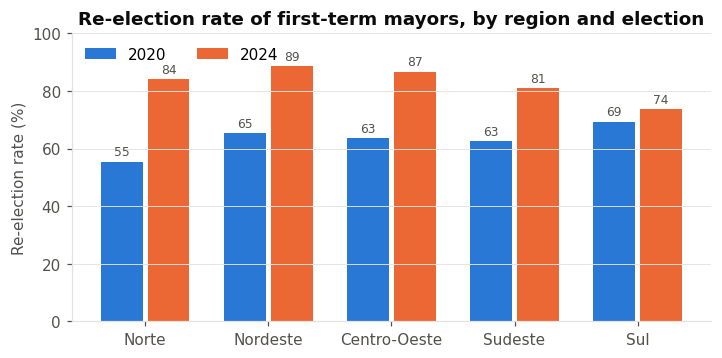

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
taxa = base.groupby(["regiao", "ano"])[ALVO].mean().unstack().reindex(REGIOES)
x = np.arange(len(REGIOES)); w = 0.38
for i, (ano, cor) in enumerate(zip(taxa.columns, [COR["azul"], COR["laranja"]])):
    barras = ax.bar(x + (i - 0.5) * w, taxa[ano] * 100, width=w - 0.04, color=cor, label=str(ano))
    ax.bar_label(barras, fmt="%.0f", fontsize=8, color=COR["texto2"], padding=2)
ax.set_xticks(x, REGIOES)
ax.set_ylabel("Re-election rate (%)")
ax.set_ylim(0, 100)
ax.set_title("Re-election rate of first-term mayors, by region and election")
ax.legend(ncol=2, loc="upper left")
ax.grid(axis="x", visible=False)
plt.savefig("fig1_taxa_regiao.png"); plt.show()

**Leitura:** a taxa de reeleição subiu em todas as regiões de 2020 para 2024. O maior salto foi no Norte (de 55% para 84%) e o menor foi no Sul (de 69% para 74%), que em 2020 era a região com a maior taxa e em 2024 passou a ser a menor. O Nordeste teve a maior taxa em 2024 (89%). Essa diferença entre as duas eleições já mostra uma **mudança de distribuição** (a taxa de base muda de um ano para o outro), o que afeta a avaliação do modelo (seção 4).

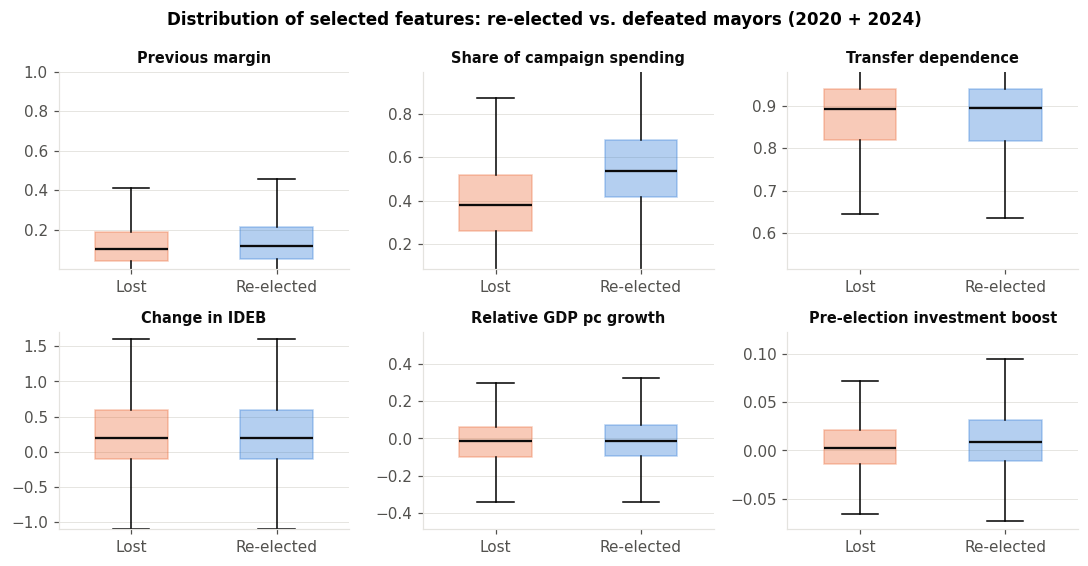

In [5]:
destaque = ["margem_anterior", "gasto_campanha_share", "dependencia_transferencias", "var_ideb",
            "cresc_pib_pc_rel", "acel_investimento"]
nomes = {"margem_anterior": "Previous margin", "gasto_campanha_share": "Share of campaign spending",
         "dependencia_transferencias": "Transfer dependence", "var_ideb": "Change in IDEB",
         "cresc_pib_pc_rel": "Relative GDP pc growth", "acel_investimento": "Pre-election investment boost"}

fig, axes = plt.subplots(2, 3, figsize=(10, 5.2))
for ax, col in zip(axes.ravel(), destaque):
    dados = [base.loc[base[ALVO] == k, col].dropna() for k in (0, 1)]
    lim = np.nanpercentile(base[col], [1, 99])
    bp = ax.boxplot(dados, showfliers=False, widths=0.5, patch_artist=True)
    ax.set_xticks([1, 2], ["Lost", "Re-elected"])
    for caixa, cor in zip(bp["boxes"], [COR["laranja"], COR["azul"]]):
        caixa.set(facecolor=cor, alpha=0.35, edgecolor=cor)
    for med in bp["medians"]:
        med.set(color=COR["texto"], linewidth=1.5)
    ax.set_ylim(*lim)
    ax.set_title(nomes[col], fontsize=9.5)
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribution of selected features: re-elected vs. defeated mayors (2020 + 2024)",
             fontweight="bold", fontsize=11)
plt.tight_layout(); plt.savefig("fig2_boxplots.png"); plt.show()

**Leitura:** a variável que mais separa reeleitos de derrotados é a participação no gasto de campanha (mediana de 0,54 entre os reeleitos contra 0,38 entre os derrotados). A margem da eleição anterior é um pouco maior entre os reeleitos (0,115 contra 0,101), mas as caixas se sobrepõem bastante. Dependência de transferências, variação do IDEB e crescimento do PIB têm caixas praticamente iguais nos dois grupos, ou seja, sozinhas não ajudam a separar quem ganha de quem perde.

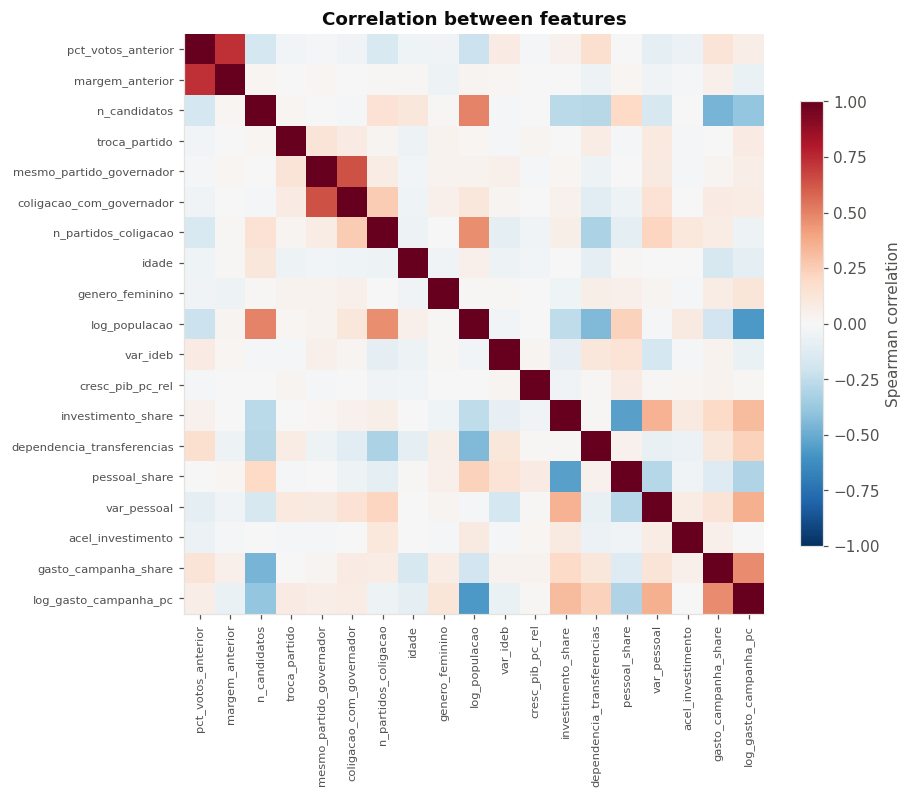

Pares mais correlacionados (|rho| > 0.6):
pct_votos_anterior        margem_anterior             0.73
mesmo_partido_governador  coligacao_com_governador    0.64


In [6]:
continuas = [c for c in TODAS if not c.startswith("regiao_")]
corr = base[continuas].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)          # divergente: dois polos e centro neutro
ax.set_xticks(range(len(continuas)), continuas, rotation=90, fontsize=7.5)
ax.set_yticks(range(len(continuas)), continuas, fontsize=7.5)
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.75, label="Spearman correlation")
ax.set_title("Correlation between features")
plt.savefig("fig3_correlacao.png"); plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack()
print("Pares mais correlacionados (|rho| > 0.6):")
print(pares[pares.abs() > 0.6].sort_values(key=abs, ascending=False).round(2).to_string())

In [7]:
# Taxa de reeleição por faixas de algumas variáveis: mostra a DIREÇÃO das associações,
# que a importância por permutação (seção 7) não informa.
faixas = {
    "idade": [0, 40, 50, 60, 100],
    "gasto_campanha_share": [0, 0.25, 0.5, 0.75, 1.01],
    "n_partidos_coligacao": [0, 2, 5, 10, 100],
}
for col, cortes in faixas.items():
    tab = base.groupby([pd.cut(base[col], cortes), "ano"], observed=True)[ALVO].agg(["mean", "size"]).unstack()
    print(f"\nTaxa de reeleição por faixa de {col}:")
    print(tab.round(3).to_string())
print("\nTaxa de reeleição por gênero (1 = feminino):")
print(base.groupby(["genero_feminino", "ano"])[ALVO].agg(["mean", "size"]).unstack().round(3).to_string())


Taxa de reeleição por faixa de idade:
            mean         size     
ano         2020   2024  2020 2024
idade                             
(0, 40]    0.740  0.915   443  402
(40, 50]   0.684  0.888   858  776
(50, 60]   0.628  0.812  1055  814
(60, 100]  0.544  0.723   642  632

Taxa de reeleição por faixa de gasto_campanha_share:
                       mean         size      
ano                    2020   2024  2020  2024
gasto_campanha_share                          
(0.0, 0.25]           0.323  0.420   341   150
(0.25, 0.5]           0.585  0.769  1288  1005
(0.5, 0.75]           0.746  0.891  1051  1080
(0.75, 1.01]          0.914  0.984   301   382

Taxa de reeleição por faixa de n_partidos_coligacao:
                       mean         size      
ano                    2020   2024  2020  2024
n_partidos_coligacao                          
(0, 2]                0.554  0.761  1107   556
(2, 5]                0.668  0.833  1433  1087
(5, 10]               0.769  0.866   407   8

**Leitura:** prefeitos mais jovens se reelegem mais: em 2020, 74% dos prefeitos com até 40 anos foram reeleitos, contra 54% dos acima de 60 (em 2024, 92% contra 72%). As prefeitas se reelegeram menos que os prefeitos (53% contra 66% em 2020; 79% contra 84% em 2024). A participação no gasto de campanha mostra a relação mais forte: quem tinha até 25% do gasto do município se reelegeu em 32% (2020) e 42% (2024) dos casos, e quem tinha mais de 75%, em 91% e 98%. Coligações maiores também acompanham mais reeleição. São associações (mostram a direção), não causas.

## 4. Protocolo experimental

- **Divisão temporal:** treino com a eleição de **2020**, teste com a de **2024**. É o cenário realista
  (prever uma eleição futura com o que se aprendeu da passada) e impede que informações do mesmo pleito
  apareçam no treino e no teste.
- **Ajuste de hiperparâmetros:** validação cruzada estratificada (5 partições) **somente no treino**.
  O conjunto de teste é usado uma única vez, no fim.
- **Prevenção de vazamento:** a imputação de valores ausentes e a padronização ficam **dentro** do
  *pipeline*, ou seja, são aprendidas só com os dados de treino de cada partição. Variáveis do resultado
  da eleição atual (`alvo_margem`) e identificadores não entram no modelo.
- **Métricas:** como a classe "reeleito" é majoritária (≈83% em 2024), a acurácia seria enganosa (prever
  "todos reeleitos" já acerta 83%). Usamos:
  - **ROC-AUC**: capacidade de ordenar prefeitos por chance de vitória, independente do limiar;
  - **PR-AUC das derrotas**: foca na classe minoritária, a mais difícil;
  - **Brier score**: qualidade das probabilidades (menor é melhor);
  - **Acurácia balanceada**, com limiar escolhido no treino.
- **Incerteza:** intervalos de confiança de 95% por *bootstrap* (1.000 reamostragens do conjunto de teste).

In [8]:
treino = base[base["ano"] == 2020].reset_index(drop=True)
teste = base[base["ano"] == 2024].reset_index(drop=True)
y_tr, y_te = treino[ALVO].values, teste[ALVO].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
print(f"Treino (2020): {len(treino)} prefeitos, {y_tr.mean():.1%} reeleitos")
print(f"Teste  (2024): {len(teste)} prefeitos, {y_te.mean():.1%} reeleitos")

def ic_bootstrap(metrica, y, p, n=1000):
    # Intervalo de confiança de 95% da métrica, reamostrando o conjunto de teste com reposição.
    rng = np.random.default_rng(SEMENTE)
    valores = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) == 2:
            valores.append(metrica(y[i], p[i]))
    return np.percentile(valores, [2.5, 97.5])

auc = roc_auc_score
pr_derrota = lambda y, p: average_precision_score(1 - y, 1 - p)   # derrotas como classe positiva

def limiar_otimo(y, p):
    # Limiar que maximiza a acurácia balanceada (escolhido com previsões fora da amostra do TREINO).
    grade = np.linspace(0.05, 0.95, 91)
    return grade[np.argmax([balanced_accuracy_score(y, (p >= l).astype(int)) for l in grade])]

def avaliar(nome, modelo, colunas):
    # Treina em 2020, escolhe o limiar por validação cruzada no treino e avalia uma única vez em 2024.
    p_oof = cross_val_predict(modelo, treino[colunas], y_tr, cv=cv, method="predict_proba")[:, 1]
    limiar = limiar_otimo(y_tr, p_oof)
    modelo.fit(treino[colunas], y_tr)
    p = modelo.predict_proba(teste[colunas])[:, 1]
    lo, hi = ic_bootstrap(auc, y_te, p)
    return {"modelo": nome, "AUC_cv_treino": roc_auc_score(y_tr, p_oof),
            "AUC_teste": auc(y_te, p), "AUC_IC95": f"[{lo:.3f}, {hi:.3f}]",
            "PR_AUC_derrotas": pr_derrota(y_te, p), "PR_base_derrotas": 1 - y_te.mean(),
            "Brier": brier_score_loss(y_te, p), "Acur_balanceada": balanced_accuracy_score(y_te, (p >= limiar).astype(int)),
            "limiar": limiar}, p

Treino (2020): 2998 prefeitos, 64.3% reeleitos
Teste  (2024): 2624 prefeitos, 82.9% reeleitos


## 5. Modelos

1. **Baseline ingênuo** (`DummyClassifier`): prevê sempre a taxa de reeleição do treino. Define o piso
   (AUC = 0,5).
2. **Baseline de intuição política**: regressão logística usando **apenas** a margem da eleição anterior
   ("prefeito que ganhou com folga tende a se reeleger").
3. **Regressão logística** com todos os atributos: modelo linear e interpretável.
4. **Gradient boosting** (`HistGradientBoostingClassifier`): conjunto de árvores de decisão treinadas em
   sequência, cada uma corrigindo os erros das anteriores. Capta relações não lineares e interações, e
   trata valores ausentes nativamente.

Os hiperparâmetros dos modelos 3 e 4 são escolhidos por validação cruzada no treino (busca em grade,
critério ROC-AUC).

In [9]:
def logistica(C=1.0):
    return make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                         LogisticRegression(C=C, max_iter=5000))

busca_lr = GridSearchCV(logistica(), {"logisticregression__C": [0.01, 0.1, 1, 10]},
                        scoring="roc_auc", cv=cv).fit(treino[TODAS], y_tr)
C_LR = busca_lr.best_params_["logisticregression__C"]

grade_gb = {"learning_rate": [0.03, 0.1], "max_leaf_nodes": [8, 15, 31],
            "min_samples_leaf": [20, 60], "l2_regularization": [0.0, 1.0], "max_iter": [150, 400]}
busca_gb = GridSearchCV(HistGradientBoostingClassifier(random_state=SEMENTE), grade_gb,
                        scoring="roc_auc", cv=cv, n_jobs=-1).fit(treino[TODAS], y_tr)
PARAM_GB = busca_gb.best_params_
gb = lambda: HistGradientBoostingClassifier(random_state=SEMENTE, **PARAM_GB)

print("Regressão logística — melhor C:", C_LR, "| AUC CV:", round(busca_lr.best_score_, 3))
print("Gradient boosting — melhores hiperparâmetros:", PARAM_GB, "| AUC CV:", round(busca_gb.best_score_, 3))

Regressão logística — melhor C: 1 | AUC CV: 0.744
Gradient boosting — melhores hiperparâmetros: {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_iter': 150, 'max_leaf_nodes': 8, 'min_samples_leaf': 60} | AUC CV: 0.746


In [10]:
resultados, prev = [], {}
for nome, modelo, colunas in [
    ("Naive baseline (prior)", DummyClassifier(strategy="prior"), TODAS),
    ("Previous margin only (logistic)", logistica(), ["margem_anterior"]),
    ("Logistic regression (all)", logistica(C_LR), TODAS),
    ("Gradient boosting (all)", gb(), TODAS),
    ("Logistic regression (pre-campaign)", logistica(C_LR), PRE_CAMPANHA),
    ("Gradient boosting (pre-campaign)", gb(), PRE_CAMPANHA),
]:
    r, p = avaliar(nome, modelo, colunas)
    resultados.append(r); prev[nome] = p

tabela_modelos = pd.DataFrame(resultados).set_index("modelo")
tabela_modelos.round(3)

,AUC_cv_treino,AUC_teste,AUC_IC95,PR_AUC_derrotas,PR_base_derrotas,Brier,Acur_balanceada,limiar
modelo,,,,,,,,
Naive baseline (prior),0.499,0.500,"[0.500, 0.500]",0.171,0.171,0.176,0.500,0.05
Previous margin only (logistic),0.550,0.547,"[0.519, 0.578]",0.201,0.171,0.178,0.533,0.63
Logistic regression (all),0.743,0.760,"[0.736, 0.783]",0.434,0.171,0.139,0.674,0.66
Gradient boosting (all),0.745,0.767,"[0.744, 0.789]",0.429,0.171,0.139,0.686,0.67
Logistic regression (pre-campaign),0.677,0.673,"[0.645, 0.701]",0.337,0.171,0.138,0.602,0.63
Gradient boosting (pre-campaign),0.689,0.668,"[0.639, 0.697]",0.335,0.171,0.144,0.609,0.65


**Leitura:** os dois modelos completos superam com folga os baselines: AUC de 0,767 (gradient boosting) e 0,760 (regressão logística), contra 0,500 do ingênuo e 0,547 usando só a margem anterior. Ou seja, ter ganhado com folga quatro anos antes quase não ajuda a prever. O gradient boosting praticamente empata com a logística, então relações não lineares acrescentam pouco. A PR-AUC das derrotas (0,43) é cerca de 2,5 vezes a de um modelo aleatório (0,171). No cenário pré-campanha (sem o gasto de campanha), a AUC cai para cerca de 0,67.

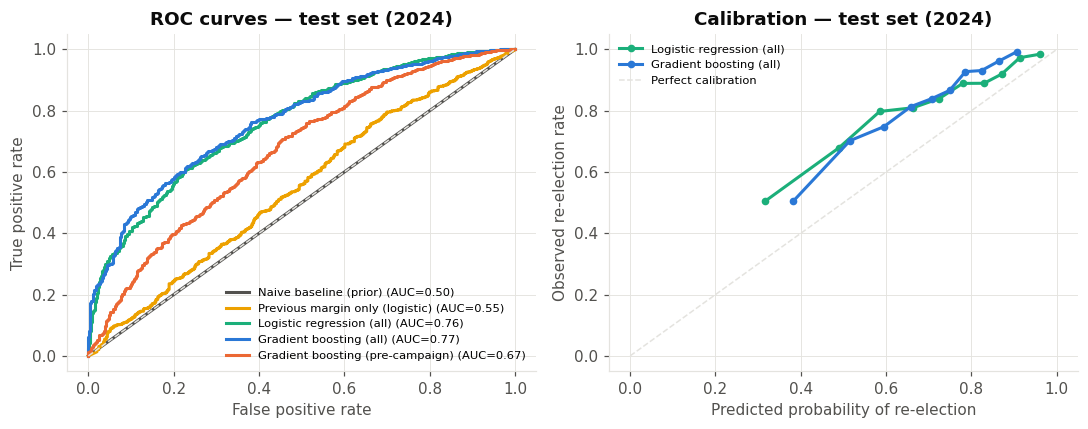

Logistic regression (all): probabilidade média prevista = 71.4% | taxa real em 2024 = 82.9%
Gradient boosting (all): probabilidade média prevista = 69.9% | taxa real em 2024 = 82.9%


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
curvas = {"Naive baseline (prior)": COR["texto2"], "Previous margin only (logistic)": COR["amarelo"],
          "Logistic regression (all)": COR["verde"], "Gradient boosting (all)": COR["azul"],
          "Gradient boosting (pre-campaign)": COR["laranja"]}
for nome, cor in curvas.items():
    p = prev[nome]
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC={roc_auc_score(y_te, p):.2f})")
axes[0].plot([0, 1], [0, 1], ls="--", color=COR["grade"], lw=1)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves — test set (2024)")
axes[0].legend(fontsize=7.5, loc="lower right")

for nome, cor in [("Logistic regression (all)", COR["verde"]), ("Gradient boosting (all)", COR["azul"])]:
    frac, media = calibration_curve(y_te, prev[nome], n_bins=10, strategy="quantile")
    axes[1].plot(media, frac, marker="o", ms=4, lw=2, color=cor, label=nome)
axes[1].plot([0, 1], [0, 1], ls="--", color=COR["grade"], lw=1, label="Perfect calibration")
axes[1].set(xlabel="Predicted probability of re-election", ylabel="Observed re-election rate",
            title="Calibration — test set (2024)")
axes[1].legend(fontsize=7.5, loc="upper left")
plt.tight_layout(); plt.savefig("fig4_roc_calibracao.png"); plt.show()

for nome in ["Logistic regression (all)", "Gradient boosting (all)"]:
    print(f"{nome}: probabilidade média prevista = {prev[nome].mean():.1%} | taxa real em 2024 = {y_te.mean():.1%}")

**Leitura da calibração:** as probabilidades ficam abaixo da taxa real: o gradient boosting prevê em média 69,9% de chance de reeleição (a regressão logística, 71,4%), mas 82,9% dos prefeitos foram reeleitos em 2024. Isso acontece porque o modelo aprendeu com 2020, quando só 64% se reelegeram, e não tinha como saber que 2024 seria uma eleição recorde. O modelo ordena bem os prefeitos (AUC), mas o nível das probabilidades acompanha a eleição de treino, então precisaria ser recalibrado a cada eleição.

## 6. Contribuição principal: comparação entre blocos de atributos

Treinamos o mesmo gradient boosting (mesmos hiperparâmetros) com cada bloco **isolado** e com todos menos
um bloco (**ablação**). Comparamos a AUC no teste de 2024, com intervalo de confiança.

- **Bloco isolado**: quanta informação o bloco carrega sozinho.
- **Todos menos um bloco**: quanta informação **exclusiva** o bloco acrescenta, que os outros não cobrem.

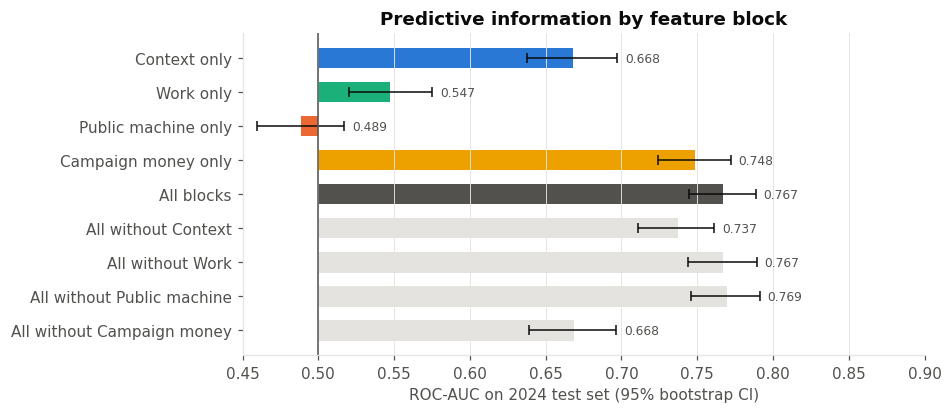

,n_atributos,AUC_teste,IC95_inf,IC95_sup,PR_AUC_derrotas
configuração,,,,,
Context only,15,0.668,0.638,0.697,0.350
Work only,3,0.547,0.520,0.575,0.199
Public machine only,4,0.489,0.459,0.517,0.173
Campaign money only,2,0.748,0.724,0.772,0.405
All blocks,24,0.767,0.744,0.789,0.429
All without Context,9,0.737,0.711,0.761,0.375
All without Work,21,0.767,0.744,0.789,0.445
All without Public machine,20,0.769,0.746,0.791,0.426
All without Campaign money,22,0.668,0.639,0.697,0.335


In [12]:
linhas, prev_bloco = [], {}
configs = [(f"{b} only", cols) for b, cols in BLOCOS.items()] + [("All blocks", TODAS)] + \
          [(f"All without {b}", [c for c in TODAS if c not in cols]) for b, cols in BLOCOS.items()]
for nome, cols in configs:
    modelo = gb().fit(treino[cols], y_tr)
    p = modelo.predict_proba(teste[cols])[:, 1]
    lo, hi = ic_bootstrap(auc, y_te, p)
    linhas.append({"configuração": nome, "n_atributos": len(cols), "AUC_teste": auc(y_te, p),
                   "IC95_inf": lo, "IC95_sup": hi, "PR_AUC_derrotas": pr_derrota(y_te, p)})
    prev_bloco[nome] = p
tabela_blocos = pd.DataFrame(linhas).set_index("configuração")

fig, ax = plt.subplots(figsize=(8, 3.8))
t = tabela_blocos.iloc[::-1]
cores = [cor_da_config(n) for n in t.index]
ax.barh(t.index, t["AUC_teste"] - 0.5, left=0.5, height=0.6, color=cores)
ax.errorbar(t["AUC_teste"], np.arange(len(t)), xerr=[t["AUC_teste"] - t["IC95_inf"], t["IC95_sup"] - t["AUC_teste"]],
            fmt="none", ecolor=COR["texto"], elinewidth=1, capsize=3)
for i, v in enumerate(t["AUC_teste"]):
    ax.text(t["IC95_sup"].iloc[i] + 0.005, i, f"{v:.3f}", va="center", fontsize=8, color=COR["texto2"])
ax.axvline(0.5, color=COR["texto2"], lw=1)
ax.set_xlim(0.45, max(0.9, t["IC95_sup"].max() + 0.05))
ax.set_xlabel("ROC-AUC on 2024 test set (95% bootstrap CI)")
ax.set_title("Predictive information by feature block")
ax.grid(axis="y", visible=False)
plt.savefig("fig5_blocos.png"); plt.show()
tabela_blocos.round(3)

**Leitura:** o dinheiro de campanha sozinho (0,748) chega quase no modelo completo (0,767). O contexto vem em segundo (0,668). O trabalho fica pouco acima do acaso (0,547) e a máquina pública fica no nível do acaso (0,489). Na ablação, tirar o trabalho ou a máquina pública não muda nada (0,767 e 0,769), enquanto tirar o dinheiro de campanha derruba a AUC para 0,668. Os intervalos de confiança do trabalho e da máquina pública não se sobrepõem ao do dinheiro de campanha, então essa diferença é clara. Quase toda a informação vem do gasto de campanha, que também funciona como termômetro da disputa (quem é favorito arrecada mais).

## 7. Quais variáveis pesam? (importância por permutação)

A **importância por permutação** embaralha os valores de uma coluna no conjunto de teste e mede quanto a
AUC cai. Se embaralhar uma variável não muda nada, o modelo não depende dela. É um método simples,
que funciona com qualquer modelo e é calculado nos dados de teste.

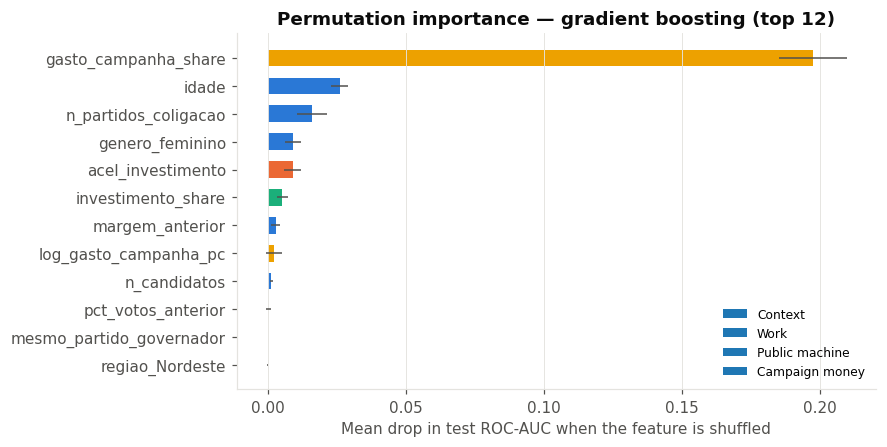

,variavel,queda_AUC,dp,bloco
22,gasto_campanha_share,0.1975,0.0123,Campaign money
7,idade,0.0262,0.0031,Context
6,n_partidos_coligacao,0.0160,0.0055,Context
8,genero_feminino,0.0092,0.0028,Context
21,acel_investimento,0.0091,0.0032,Public machine
17,investimento_share,0.0053,0.0020,Work
1,margem_anterior,0.0030,0.0016,Context
23,log_gasto_campanha_pc,0.0024,0.0030,Campaign money
2,n_candidatos,0.0013,0.0006,Context
0,pct_votos_anterior,0.0002,0.0008,Context


In [13]:
modelo_final = gb().fit(treino[TODAS], y_tr)
imp = permutation_importance(modelo_final, teste[TODAS], y_te, scoring="roc_auc",
                             n_repeats=30, random_state=SEMENTE, n_jobs=-1)
bloco_de = {c: b for b, cols in BLOCOS.items() for c in cols}
importancias = (pd.DataFrame({"variavel": TODAS, "queda_AUC": imp.importances_mean, "dp": imp.importances_std})
                .assign(bloco=lambda d: d["variavel"].map(bloco_de))
                .sort_values("queda_AUC", ascending=False))

top = importancias.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(top["variavel"], top["queda_AUC"], xerr=top["dp"], height=0.6,
        color=[COR_BLOCO[b] for b in top["bloco"]], error_kw={"elinewidth": 1, "ecolor": COR["texto2"]})
for b in BLOCOS:
    ax.barh([], [], color=COR_BLOCO[b], label=b)
ax.legend(loc="lower right", fontsize=8)
ax.set_xlabel("Mean drop in test ROC-AUC when the feature is shuffled")
ax.set_title("Permutation importance — gradient boosting (top 12)")
ax.grid(axis="y", visible=False)
plt.savefig("fig6_importancia.png"); plt.show()
importancias.round(4).head(15)

**Leitura:** a participação no gasto de campanha domina (queda de 0,198 na AUC quando é embaralhada), muito acima das próximas: idade (0,026), tamanho da coligação (0,016), gênero (0,009) e aceleração do investimento (0,009). A surpresa é que a margem da eleição anterior quase não pesa (0,003). Como `pct_votos_anterior` e `margem_anterior` são muito correlacionadas (0,73), elas dividem a importância entre si, então o peso de cada uma isolada pode parecer menor do que é.

## 8. O padrão muda conforme o perfil do município?

Avaliamos o modelo completo e os blocos isolados em subgrupos do conjunto de teste:

- **Porte**: faixas de população (até 10 mil, 10–50 mil, 50–200 mil, acima de 200 mil habitantes);
- **Dependência fiscal**: tercis de `dependencia_transferencias` (limites calculados no **treino**);
- **Região**, com destaque para o Nordeste e o Piauí.

Subgrupos pequenos têm intervalos de confiança largos; a coluna `n` mostra o tamanho de cada um.

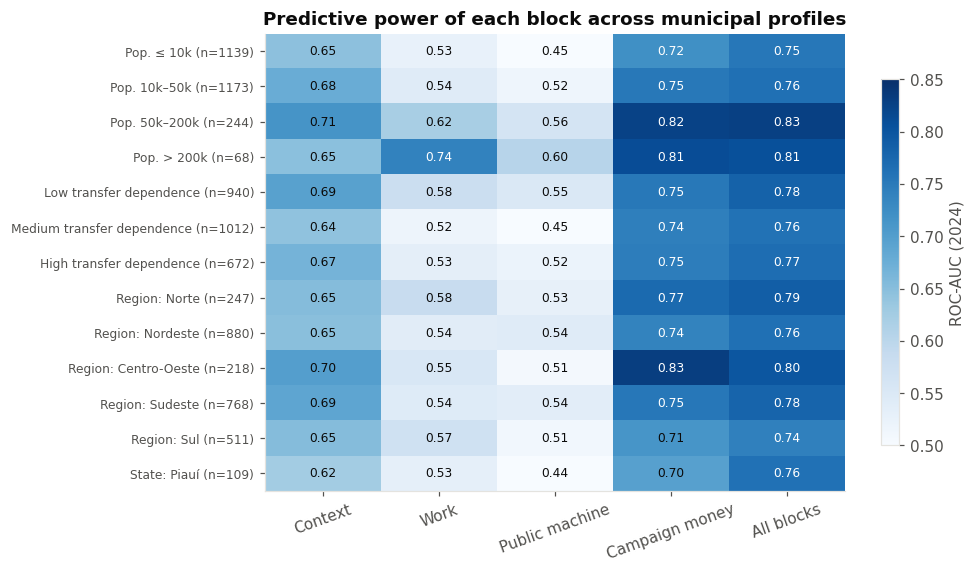

,n,taxa_reeleicao,Context only,Work only,Public machine only,Campaign money only,All blocks,IC95 (All)
subgrupo,,,,,,,,
Pop. ≤ 10k,1139,0.818,0.646,0.525,0.448,0.721,0.753,"[0.72, 0.79]"
Pop. 10k–50k,1173,0.845,0.676,0.542,0.515,0.752,0.764,"[0.73, 0.80]"
Pop. 50k–200k,244,0.816,0.714,0.619,0.562,0.825,0.828,"[0.74, 0.89]"
Pop. > 200k,68,0.779,0.647,0.738,0.604,0.811,0.806,"[0.65, 0.91]"
Low transfer dependence,940,0.795,0.694,0.579,0.550,0.753,0.782,"[0.75, 0.82]"
Medium transfer dependence,1012,0.831,0.642,0.517,0.453,0.743,0.761,"[0.73, 0.79]"
High transfer dependence,672,0.874,0.666,0.534,0.522,0.745,0.767,"[0.72, 0.82]"
Region: Norte,247,0.842,0.652,0.583,0.528,0.772,0.788,"[0.71, 0.86]"
Region: Nordeste,880,0.888,0.649,0.539,0.542,0.737,0.764,"[0.72, 0.81]"


In [14]:
pop = np.exp(teste["log_populacao"])
grupos = {
    "Pop. ≤ 10k": pop <= 10_000, "Pop. 10k–50k": (pop > 10_000) & (pop <= 50_000),
    "Pop. 50k–200k": (pop > 50_000) & (pop <= 200_000), "Pop. > 200k": pop > 200_000,
}
cortes = treino["dependencia_transferencias"].quantile([1 / 3, 2 / 3]).values
dep = teste["dependencia_transferencias"]
grupos.update({"Low transfer dependence": dep <= cortes[0],
               "Medium transfer dependence": (dep > cortes[0]) & (dep <= cortes[1]),
               "High transfer dependence": dep > cortes[1]})
grupos.update({f"Region: {r}": teste["regiao"] == r for r in REGIOES})
grupos["State: Piauí"] = teste["sigla_uf"] == "PI"

linhas = []
for g, mascara in grupos.items():
    m = mascara.fillna(False).values
    if m.sum() < 30 or len(np.unique(y_te[m])) < 2:
        continue
    linha = {"subgrupo": g, "n": int(m.sum()), "taxa_reeleicao": y_te[m].mean()}
    for nome in [f"{b} only" for b in BLOCOS] + ["All blocks"]:
        linha[nome] = roc_auc_score(y_te[m], prev_bloco[nome][m])
    lo, hi = ic_bootstrap(auc, y_te[m], prev_bloco["All blocks"][m], n=500)
    linha["IC95 (All)"] = f"[{lo:.2f}, {hi:.2f}]"
    linhas.append(linha)
tabela_sub = pd.DataFrame(linhas).set_index("subgrupo")

fig, ax = plt.subplots(figsize=(8.5, 5.4))
mat = tabela_sub[[f"{b} only" for b in BLOCOS] + ["All blocks"]]
im = ax.imshow(mat.values, cmap="Blues", vmin=0.5, vmax=max(0.85, np.nanmax(mat.values)), aspect="auto")
ax.set_xticks(range(mat.shape[1]), [c.replace(" only", "") for c in mat.columns], rotation=20)
ax.set_yticks(range(mat.shape[0]), [f"{s} (n={n})" for s, n in zip(mat.index, tabela_sub["n"])], fontsize=8)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.72 else COR["texto"])
ax.grid(False)
plt.colorbar(im, ax=ax, shrink=0.8, label="ROC-AUC (2024)")
ax.set_title("Predictive power of each block across municipal profiles")
plt.savefig("fig7_subgrupos.png"); plt.show()
tabela_sub.round(3)

**Leitura:** o modelo completo funciona parecido em todos os perfis (AUC entre 0,74 e 0,83), e o dinheiro de campanha é o bloco mais forte em todos eles. A dependência de transferências não muda o padrão: a máquina pública continua sem informação nos três grupos, mesmo com as cidades mais dependentes reelegendo mais (87% contra 80%). O que muda é o bloco trabalho, que prevê mais conforme a cidade cresce (0,53 até 10 mil habitantes, 0,62 entre 50 e 200 mil e 0,74 acima de 200 mil). Uma explicação possível é que nas cidades grandes o desempenho é mais visível (mais imprensa local), mas como são só 68 cidades acima de 200 mil (o intervalo de confiança do modelo completo nesse grupo vai de 0,65 a 0,91), isso é um indício e não uma conclusão. No Piauí, o modelo completo teve AUC de 0,76 com 109 prefeitos.

## 9. Análise de erros

Comparamos os prefeitos em que o modelo **errou com confiança** com os acertos:

- **Derrotas inesperadas**: o modelo dava alta chance de reeleição, mas o prefeito perdeu;
- **Vitórias inesperadas**: o modelo dava baixa chance, mas o prefeito venceu.

In [15]:
p_final = modelo_final.predict_proba(teste[TODAS])[:, 1]
limiar = tabela_modelos.loc["Gradient boosting (all)", "limiar"]
pred = (p_final >= limiar).astype(int)
mc = confusion_matrix(y_te, pred)
print(f"Limiar (escolhido no treino): {limiar:.2f}")
print(pd.DataFrame(mc, index=["Real: perdeu", "Real: reeleito"], columns=["Previsto: perde", "Previsto: reeleito"]))

analise = teste.assign(prob=p_final)
analise["grupo"] = np.select(
    [(analise[ALVO] == 0) & (analise["prob"] >= 0.8), (analise[ALVO] == 1) & (analise["prob"] < 0.5),
     (analise[ALVO] == 1) & (analise["prob"] >= 0.8), (analise[ALVO] == 0) & (analise["prob"] < 0.5)],
    ["Derrota inesperada", "Vitória inesperada", "Vitória prevista", "Derrota prevista"], "Intermediário")
cols_erro = ["prob", "margem_anterior", "n_candidatos", "gasto_campanha_share", "coligacao_com_governador",
             "troca_partido", "dependencia_transferencias", "var_ideb", "log_populacao"]
erros = analise.groupby("grupo")[cols_erro].median().assign(n=analise["grupo"].value_counts())
erros.round(3)

Limiar (escolhido no treino): 0.67
                Previsto: perde  Previsto: reeleito
Real: perdeu                305                 144
Real: reeleito              668                1507


,prob,margem_anterior,n_candidatos,gasto_campanha_share,coligacao_com_governador,troca_partido,dependencia_transferencias,var_ideb,log_populacao,n
grupo,,,,,,,,,,
Derrota inesperada,0.834,0.129,2.0,0.615,0.0,0.0,0.849,-0.15,9.527,33
Derrota prevista,0.414,0.079,3.0,0.259,0.0,1.0,0.871,-0.10,9.208,160
Intermediário,0.689,0.094,2.0,0.493,0.0,0.0,0.887,0.10,9.312,1464
Vitória inesperada,0.443,0.073,3.0,0.342,0.0,1.0,0.908,0.00,8.932,187
Vitória prevista,0.864,0.130,2.0,0.744,1.0,0.0,0.887,0.10,9.528,780


**Leitura:** as 33 derrotas inesperadas (o modelo dava 80% ou mais de chance, mas o prefeito perdeu) tinham gasto alto (mediana de 0,62 do gasto do município), mas, ao contrário das vitórias previstas, não tinham coligação com o partido do governador e tiveram queda no IDEB (−0,15). As 187 vitórias inesperadas (menos de 50% de chance, mas venceu) aparecem em cidades menores e mais dependentes de transferências, com menos gasto (0,34) e com troca de partido. Muitos desses casos devem ser explicados por fatores que não estão nos dados, como escândalos, a força do candidato adversário, alianças locais e a avaliação do governo.

## 10. Robustez

1. **Direção temporal invertida**: treinar em 2024 e testar em 2020. Se a AUC se mantém, o padrão
   aprendido não é exclusivo de uma eleição.
2. **Validação cruzada dentro de cada eleição**: mede o desempenho sem mudança de distribuição entre anos.

In [16]:
linhas = []
for nome, modelo in [("Logistic regression", logistica(C_LR)), ("Gradient boosting", gb())]:
    m = modelo.fit(teste[TODAS], y_te)
    p_inv = m.predict_proba(treino[TODAS])[:, 1]
    linha = {"modelo": nome, "Treino 2020 → teste 2024": roc_auc_score(y_te, prev[f"{nome} (all)"]),
             "Treino 2024 → teste 2020": roc_auc_score(y_tr, p_inv)}
    for ano, d in [(2020, treino), (2024, teste)]:
        p_cv = cross_val_predict(modelo, d[TODAS], d[ALVO], cv=cv, method="predict_proba")[:, 1]
        linha[f"CV dentro de {ano}"] = roc_auc_score(d[ALVO], p_cv)
    linhas.append(linha)
tabela_robustez = pd.DataFrame(linhas).set_index("modelo")
tabela_robustez.round(3)

,Treino 2020 → teste 2024,Treino 2024 → teste 2020,CV dentro de 2020,CV dentro de 2024
modelo,,,,
Logistic regression,0.760,0.720,0.743,0.783
Gradient boosting,0.767,0.738,0.745,0.775


## 11. Resumo dos resultados

A célula abaixo junta os números principais (usados no artigo).

In [17]:
pd.set_option("display.width", 200)
print("=== AMOSTRA ===");            print(resumo.round(3).to_string())
print("\n=== HIPERPARÂMETROS ===");   print("LR C =", C_LR, "| GB =", PARAM_GB)
print("\n=== MODELOS (teste 2024) ==="); print(tabela_modelos.round(3).to_string())
print("\n=== BLOCOS ===");            print(tabela_blocos.round(3).to_string())
print("\n=== IMPORTÂNCIA (top 15) ==="); print(importancias.head(15).round(4).to_string(index=False))
print("\n=== SUBGRUPOS ===");         print(tabela_sub.round(3).to_string())
print("\n=== ERROS ===");             print(erros.round(3).to_string())
print("\n=== ROBUSTEZ ===");          print(tabela_robustez.round(3).to_string())

=== AMOSTRA ===
      prefeitos  taxa_reeleicao
ano                            
2020       2998           0.643
2024       2624           0.829

=== HIPERPARÂMETROS ===
LR C = 1 | GB = {'l2_regularization': 1.0, 'learning_rate': 0.03, 'max_iter': 150, 'max_leaf_nodes': 8, 'min_samples_leaf': 60}

=== MODELOS (teste 2024) ===
                                    AUC_cv_treino  AUC_teste        AUC_IC95  PR_AUC_derrotas  PR_base_derrotas  Brier  Acur_balanceada  limiar
modelo                                                                                                                                         
Naive baseline (prior)                      0.499      0.500  [0.500, 0.500]            0.171             0.171  0.176            0.500    0.05
Previous margin only (logistic)             0.550      0.547  [0.519, 0.578]            0.201             0.171  0.178            0.533    0.63
Logistic regression (all)                   0.743      0.760  [0.736, 0.783]            0.434    

In [18]:
# Empacota as figuras (para o artigo e os slides) e baixa
import zipfile, glob
with zipfile.ZipFile("figuras.zip", "w") as z:
    for f in sorted(glob.glob("fig*.png")):
        z.write(f)
try:
    from google.colab import files
    files.download("figuras.zip")
except ImportError:
    pass

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusões



- **Desempenho:** O gradient boosting chegou a uma AUC de 0,767 no teste de 2024 (treinado só com a eleição de 2020), bem acima dos baselines (0,500 do ingênuo e 0,547 usando só a margem da eleição anterior). A regressão logística ficou praticamente empatada (0,760), ou seja, relações não lineares acrescentam pouco. Na classe mais difícil, a dos prefeitos derrotados, a PR-AUC foi de 0,43, contra 0,17 de um modelo aleatório. Nos testes de robustez o resultado ficou sempre entre 0,72 e 0,78. O ponto fraco é a calibração: o modelo previu em média 70% de chance de reeleição, mas a taxa real em 2024 foi de 83%, porque ele aprendeu com uma eleição em que só 64% se reelegeram.
- **Resposta à pergunta de pesquisa:** o bloco que mais carrega informação é o dinheiro de campanha (AUC de 0,748 sozinho, quase o modelo completo), seguido do contexto político (0,668). Os indicadores de trabalho (0,547) e de máquina pública (0,489, o mesmo que o acaso) quase não ajudam a prever, e tirar esses blocos do modelo não muda o resultado. Sem o dinheiro de campanha, a AUC cai para 0,668. Isso não quer dizer que o dinheiro compra a eleição: o gasto é medido durante a campanha, e os doadores tendem a apostar em quem já é favorito, então ele funciona em boa parte como um termômetro da disputa. Quanto ao perfil dos municípios, o padrão é parecido em todas as regiões e níveis de dependência de transferências. A única diferença é que o bloco trabalho prevê mais nas cidades grandes (0,74 acima de 200 mil habitantes), mas como são só 68 cidades, isso é um indício e não uma conclusão.
- **Limitações:** previsão não é causalidade; amostra restrita a prefeitos que decidiram concorrer (quem
  desistiu por esperar derrota não aparece — viés de seleção); indicadores fiscais declarados pelos
  próprios municípios; ausência de variáveis como escândalos, avaliação de governo e força da oposição;
  apenas duas eleições, uma delas durante a pandemia (2020).
- **Riscos e uso responsável:** o modelo não deve ser usado para "prever vencedores" em campanhas nem
  para rotular gestões; a mudança de taxa de base entre eleições exige recalibração.
- **Próximos passos:** incluir 2016 e emprego formal (RAIS); variáveis de saúde; modelos de margem de votos.